# UCI HAR: K-Means after PCA
Run all cells from top to bottom beside the `UCI HAR Dataset` folder.

First standardize the features and use PCA to retain **90% of training variance**. Then fit K-Means from scratch for K = 2, 3, 4, 5, 6. Scikit-learn provides the short PCA preprocessing step and a K-Means reference. Detailed PCA calculations and plots are in `PCA_HAR.ipynb`.

All transformations are learned from train only. Activity labels and test data do not select the model. No pipelines are used.

## 1. Understand the dataset
The local README describes 30 volunteers performing six activities with a smartphone on their waist. Accelerometer and gyroscope readings were collected at 50 Hz. Each example is a 2.56-second window with 50% overlap.

`X_train.txt` and `X_test.txt` already contain 561 extracted features, including means, standard deviations, energy, correlations and frequency measurements. Prefix `t` means time domain and `f` means frequency domain. The values are bounded within [-1, 1]. We use these features rather than the raw 128-reading signals in `Inertial Signals`.

`y_train.txt` and `y_test.txt` contain activity labels. Subject files identify participants; they are not model inputs. The supplied split separates participants, so we keep it.

Dataset source: Anguita et al., *A Public Domain Dataset for Human Activity Recognition Using Smartphones*, ESANN 2013, as cited in the local README.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

DATA_DIR = Path("UCI HAR Dataset")
OUTPUT_DIR = Path("har_results/kmeans_after_pca")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

## 2. Read features, activities and both data splits
Some names in `features.txt` repeat. Adding the feature number gives each column a unique name without dropping any features.

In [2]:
features = pd.read_csv(DATA_DIR / "features.txt", sep=r"\s+", header=None,
                       names=["Number", "Feature"])
activities = pd.read_csv(DATA_DIR / "activity_labels.txt", sep=r"\s+", header=None,
                         names=["Label", "Activity"])
feature_names = features["Number"].astype(str) + "_" + features["Feature"]

X_train = np.loadtxt(DATA_DIR / "train/X_train.txt")
X_test = np.loadtxt(DATA_DIR / "test/X_test.txt")
y_train = np.loadtxt(DATA_DIR / "train/y_train.txt", dtype=int)
y_test = np.loadtxt(DATA_DIR / "test/y_test.txt", dtype=int)
subject_train = np.loadtxt(DATA_DIR / "train/subject_train.txt", dtype=int)
subject_test = np.loadtxt(DATA_DIR / "test/subject_test.txt", dtype=int)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Missing or infinite training values:", np.sum(~np.isfinite(X_train)))
print("Missing or infinite test values:", np.sum(~np.isfinite(X_test)))
print("Subjects shared by train and test:", set(subject_train) & set(subject_test))
display(activities)
display(features.head(10))
display(pd.DataFrame(X_train[:5], columns=feature_names))

Training features: (7352, 561)
Test features: (2947, 561)
Missing or infinite training values: 0
Missing or infinite test values: 0
Subjects shared by train and test: set()


,Label,Activity
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING


,Number,Feature
0,1,tBodyAcc-mean()-X
1,2,tBodyAcc-mean()-Y
2,3,tBodyAcc-mean()-Z
3,4,tBodyAcc-std()-X
4,5,tBodyAcc-std()-Y
5,6,tBodyAcc-std()-Z
6,7,tBodyAcc-mad()-X
7,8,tBodyAcc-mad()-Y
8,9,tBodyAcc-mad()-Z
9,10,tBodyAcc-max()-X


,1_tBodyAcc-mean()-X,2_tBodyAcc-mean()-Y,3_tBodyAcc-mean()-Z,4_tBodyAcc-std()-X,5_tBodyAcc-std()-Y,6_tBodyAcc-std()-Z,7_tBodyAcc-mad()-X,8_tBodyAcc-mad()-Y,9_tBodyAcc-mad()-Z,10_tBodyAcc-max()-X,11_tBodyAcc-max()-Y,12_tBodyAcc-max()-Z,13_tBodyAcc-min()-X,14_tBodyAcc-min()-Y,15_tBodyAcc-min()-Z,16_tBodyAcc-sma(),17_tBodyAcc-energy()-X,18_tBodyAcc-energy()-Y,19_tBodyAcc-energy()-Z,20_tBodyAcc-iqr()-X,21_tBodyAcc-iqr()-Y,22_tBodyAcc-iqr()-Z,23_tBodyAcc-entropy()-X,24_tBodyAcc-entropy()-Y,25_tBodyAcc-entropy()-Z,"26_tBodyAcc-arCoeff()-X,1","27_tBodyAcc-arCoeff()-X,2","28_tBodyAcc-arCoeff()-X,3","29_tBodyAcc-arCoeff()-X,4","30_tBodyAcc-arCoeff()-Y,1","31_tBodyAcc-arCoeff()-Y,2","32_tBodyAcc-arCoeff()-Y,3","33_tBodyAcc-arCoeff()-Y,4","34_tBodyAcc-arCoeff()-Z,1","35_tBodyAcc-arCoeff()-Z,2","36_tBodyAcc-arCoeff()-Z,3","37_tBodyAcc-arCoeff()-Z,4","38_tBodyAcc-correlation()-X,Y","39_tBodyAcc-correlation()-X,Z","40_tBodyAcc-correlation()-Y,Z",...,522_fBodyBodyAccJerkMag-energy(),523_fBodyBodyAccJerkMag-iqr(),524_fBodyBodyAccJerkMag-entropy(),525_fBodyBodyAccJerkMag-maxInds,526_fBodyBodyAccJerkMag-meanFreq(),527_fBodyBodyAccJerkMag-skewness(),528_fBodyBodyAccJerkMag-kurtosis(),529_fBodyBodyGyroMag-mean(),530_fBodyBodyGyroMag-std(),531_fBodyBodyGyroMag-mad(),532_fBodyBodyGyroMag-max(),533_fBodyBodyGyroMag-min(),534_fBodyBodyGyroMag-sma(),535_fBodyBodyGyroMag-energy(),536_fBodyBodyGyroMag-iqr(),537_fBodyBodyGyroMag-entropy(),538_fBodyBodyGyroMag-maxInds,539_fBodyBodyGyroMag-meanFreq(),540_fBodyBodyGyroMag-skewness(),541_fBodyBodyGyroMag-kurtosis(),542_fBodyBodyGyroJerkMag-mean(),543_fBodyBodyGyroJerkMag-std(),544_fBodyBodyGyroJerkMag-mad(),545_fBodyBodyGyroJerkMag-max(),546_fBodyBodyGyroJerkMag-min(),547_fBodyBodyGyroJerkMag-sma(),548_fBodyBodyGyroJerkMag-energy(),549_fBodyBodyGyroJerkMag-iqr(),550_fBodyBodyGyroJerkMag-entropy(),551_fBodyBodyGyroJerkMag-maxInds,552_fBodyBodyGyroJerkMag-meanFreq(),553_fBodyBodyGyroJerkMag-skewness(),554_fBodyBodyGyroJerkMag-kurtosis(),"555_angle(tBodyAccMean,gravity)","556_angle(tBodyAccJerkMean),gravityMean)","557_angle(tBodyGyroMean,gravityMean)","558_angle(tBodyGyroJerkMean,gravityMean)","559_angle(X,gravityMean)","560_angle(Y,gravityMean)","561_angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,-0.567378,-0.744413,0.852947,0.685845,0.814263,-0.965523,-0.999945,-0.999863,-0.994612,-0.994231,-0.987614,-0.943220,-0.407747,-0.679338,-0.602122,0.929294,-0.853011,0.359910,-0.058526,0.256892,-0.224848,0.264106,-0.095246,0.278851,-0.465085,0.491936,-0.190884,0.376314,0.435129,0.660790,...,-0.999918,-0.991364,-1.0,-0.936508,0.346989,-0.516080,-0.802760,-0.980135,-0.961309,-0.973653,-0.952264,-0.989498,-0.980135,-0.999240,-0.992656,-0.701291,-1.000000,-0.128989,0.586156,0.374605,-0.991990,-0.990697,-0.989941,-0.992448,-0.991048,-0.991990,-0.999937,-0.990458,-0.871306,-1.000000,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,-0.557851,-0.818409,0.849308,0.685845,0.822637,-0.981930,-0.999991,-0.999788,-0.998405,-0.999150,-0.977866,-0.948225,-0.714892,-0.500930,-0.570979,0.611627,-0.329549,0.284213,0.284595,0.115705,-0.090963,0.294310,-0.281211,0.085988,-0.022153,-0.016657,-0.220643,-0.013429,-0.072692,0.579382,...,-0.999867,-0.991134,-1.0,-0.841270,0.532061,-0.624871,-0.900160,-0.988296,-0.983322,-0.982659,-0.986321,-0.991829,-0.988296,-0.999811,-0.993979,-0.720683,-0.948718,-0.271958,-0.336310,-0.720015,-0.995854,-0.996399,-0.995442,-0.996866,-0.994440,-0.995854,-0.999981,-0.994544,-1.000000,-1.000000,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,-0.557851,-0.818409,0.843609,0.682401,0.839344,-0.983478,-0.999969,-0.999660,-0.999470,-0.997130,-0.964

,Train,Test
Activity,,
WALKING,1226,496
WALKING_UPSTAIRS,1073,471
WALKING_DOWNSTAIRS,986,420
SITTING,1286,491
STANDING,1374,532
LAYING,1407,537


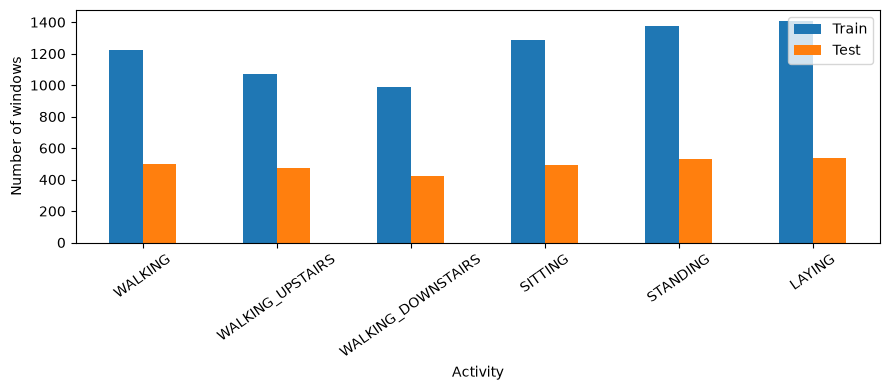

In [3]:
activity_counts = pd.DataFrame({
    "Train": pd.Series(y_train).value_counts(),
    "Test": pd.Series(y_test).value_counts()
}).sort_index()
activity_counts.index = activities["Activity"]
display(activity_counts)
activity_counts.plot(kind="bar", rot=35, figsize=(9, 4))
plt.ylabel("Number of windows")
plt.tight_layout()
plt.show()

## 3. Scale the features
Although features are bounded, their variances differ. Standardization gives each feature unit training variance before calculating distances. Fit the scaler only on train and reuse it for test. This is a modeling choice: it gives low-variance features more weight than the original bounded values would.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Apply PCA before clustering
Retain enough components to explain at least 90% of the variance. `svd_solver="full"` makes this calculation deterministic. `fit_transform` learns the directions on train; `transform` projects test onto the same directions.

Two or three components are useful for plotting but retain only about 57?60% of variance here. Clustering therefore uses more components.

In [5]:
pca = PCA(n_components=0.90, svd_solver="full")
X_train_reduced = pca.fit_transform(X_train_scaled)
X_test_reduced = pca.transform(X_test_scaled)

print("Features before PCA:", X_train_scaled.shape[1])
print("Components after PCA:", pca.n_components_)
print("Training variance retained:", pca.explained_variance_ratio_.sum())

Features before PCA: 561
Components after PCA: 63
Training variance retained: 0.9005345066145932


## 4. K-Means from scratch
The algorithm repeats two steps: assign every row to its closest centroid, then move each centroid to the mean of its assigned rows. Stop when centroids barely change, or after the iteration limit.

We start from five different random sets of centroids and keep the run with lowest WCSS. If a cluster becomes empty, its centroid is restarted at a random training row. Squared distances are enough to find the nearest centroid, so no square root is needed.

In [6]:
def assign_clusters(X, centroids):
    distances = np.zeros((len(X), len(centroids)))
    for cluster in range(len(centroids)):
        difference = X - centroids[cluster]
        distances[:, cluster] = np.sum(difference ** 2, axis=1)
    labels = np.argmin(distances, axis=1)
    return labels


def kmeans_scratch(X, k, random_state=42, n_init=5, max_iter=100):
    rng = np.random.default_rng(random_state)
    best_wcss = np.inf

    for run in range(n_init):
        starting_rows = rng.choice(len(X), size=k, replace=False)
        centroids = X[starting_rows].copy()
        converged = False

        for iteration in range(max_iter):
            labels = assign_clusters(X, centroids)
            new_centroids = centroids.copy()

            for cluster in range(k):
                members = X[labels == cluster]
                if len(members) > 0:
                    new_centroids[cluster] = members.mean(axis=0)
                else:
                    new_centroids[cluster] = X[rng.integers(len(X))]

            movement = np.max(np.abs(new_centroids - centroids))
            centroids = new_centroids
            if movement < 0.0001:
                converged = True
                break

        labels = assign_clusters(X, centroids)
        wcss = np.sum((X - centroids[labels]) ** 2)

        if wcss < best_wcss:
            best_wcss = wcss
            best_centroids = centroids.copy()
            best_labels = labels.copy()
            best_iterations = iteration + 1
            best_converged = converged

    return best_centroids, best_labels, best_wcss, best_iterations, best_converged

## 5. Try K = 2, 3, 4, 5, 6
WCSS is the sum of squared distances between training rows and their assigned centroids. Lower WCSS alone does not identify the best K because additional clusters usually reduce it.

We also measure silhouette on a fixed random sample of up to 1,500 training rows to keep computation manageable. Higher silhouette suggests more separated clusters. K is selected using this training score; the test set and activity labels do not select it. GridSearchCV is unnecessary for these five explicit trials.

All distances and WCSS values in this notebook are calculated in the retained PCA space. We do not standardize or whiten the PCA scores: higher-variance principal components keep more weight. The five random starts match the earlier experiment, so PCA is the main change.

In [7]:
k_values = [2, 3, 4, 5, 6]
centroids_by_k = {}
labels_by_k = {}
rows = []

rng = np.random.default_rng(RANDOM_STATE)
sample_rows = rng.choice(len(X_train_reduced), size=min(1500, len(X_train_reduced)), replace=False)

for k in k_values:
    centroids, labels, wcss, iterations, converged = kmeans_scratch(
        X_train_reduced, k, random_state=RANDOM_STATE
    )
    silhouette = silhouette_score(X_train_reduced[sample_rows], labels[sample_rows])
    centroids_by_k[k] = centroids
    labels_by_k[k] = labels
    rows.append([k, wcss, silhouette, iterations, converged])
    print("Finished K =", k)

results = pd.DataFrame(rows, columns=["K", "Train WCSS", "Train silhouette", "Iterations", "Converged"])
display(results)
results.to_csv(OUTPUT_DIR / "kmeans_comparison.csv", index=False)
if not results["Converged"].all():
    print("Some selected runs reached the limit. Increase max_iter and rerun before interpreting them.")

Finished K = 2
Finished K = 3
Finished K = 4
Finished K = 5
Finished K = 6


,K,Train WCSS,Train silhouette,Iterations,Converged
0,2,1.926016e+06,0.441452,3,True
1,3,1.671825e+06,0.361982,11,True
2,4,1.566572e+06,0.192210,13,True
3,5,1.509767e+06,0.164434,19,True
4,6,1.419529e+06,0.132276,29,True


## 6. Plot the elbow curve
Look for a bend where further clusters give a smaller reduction in WCSS. The elbow can be ambiguous and need not coincide with the six known activities. Silhouette provides another view, rather than proof of a uniquely correct K.

K selected by training silhouette: 2


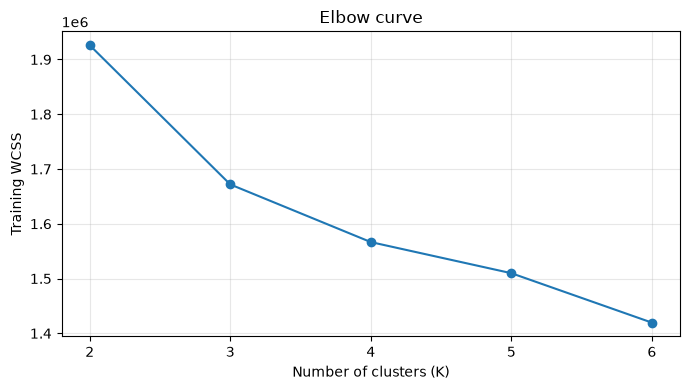

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(results["K"], results["Train WCSS"], marker="o")
plt.xticks(k_values)
plt.xlabel("Number of clusters (K)")
plt.ylabel("Training WCSS")
plt.title("Elbow curve")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "elbow_curve.png", dpi=150)
plt.show()

best_row = results["Train silhouette"].idxmax()
selected_k = int(results.loc[best_row, "K"])
print("K selected by training silhouette:", selected_k)

## 7. Evaluate on the test set
Assign test rows to the fixed training centroids. Do not refit on test. Average squared distance per row allows train/test comparison despite their different sizes.

Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) compare clusters with activity labels while allowing arbitrary cluster numbering. Higher values indicate better agreement. ARI can be negative and is around zero for chance agreement; NMI is between 0 and 1. Neither metric is ordinary classification accuracy.

In [9]:
selected_centroids = centroids_by_k[selected_k]
train_clusters = labels_by_k[selected_k]
test_clusters = assign_clusters(X_test_reduced, selected_centroids)

train_distance = np.mean(np.sum((X_train_reduced - selected_centroids[train_clusters]) ** 2, axis=1))
test_distance = np.mean(np.sum((X_test_reduced - selected_centroids[test_clusters]) ** 2, axis=1))

validation = pd.DataFrame({
    "Split": ["Train", "Test"],
    "Mean squared centroid distance": [train_distance, test_distance],
    "ARI": [adjusted_rand_score(y_train, train_clusters), adjusted_rand_score(y_test, test_clusters)],
    "NMI": [normalized_mutual_info_score(y_train, train_clusters), normalized_mutual_info_score(y_test, test_clusters)]
})
display(validation)
validation.to_csv(OUTPUT_DIR / "kmeans_validation.csv", index=False)

activity_names = dict(zip(activities["Label"], activities["Activity"]))
test_activity_names = pd.Series(y_test).map(activity_names)
cluster_table = pd.crosstab(test_activity_names, test_clusters)
cluster_table.index.name = "True activity"
cluster_table.columns.name = "Cluster"
display(cluster_table)
cluster_table.to_csv(OUTPUT_DIR / "test_activity_clusters.csv")

,Split,Mean squared centroid distance,ARI,NMI
0,Train,261.971719,0.328453,0.543257
1,Test,215.587631,0.332289,0.553689


Cluster,0,1
True activity,,
LAYING,0,537
SITTING,1,490
STANDING,0,532
WALKING,496,0
WALKING_DOWNSTAIRS,420,0
WALKING_UPSTAIRS,470,1


### A six-cluster reference
Six activities do not guarantee six natural distance-based clusters. The following table shows the already-fitted K = 6 solution as a descriptive reference. It does not change our selected K using test results.

In [10]:
six_test_clusters = assign_clusters(X_test_reduced, centroids_by_k[6])
display(pd.crosstab(test_activity_names, six_test_clusters))
print("K = 6 test ARI:", adjusted_rand_score(y_test, six_test_clusters))
print("K = 6 test NMI:", normalized_mutual_info_score(y_test, six_test_clusters))

K = 6 test ARI: 0.3752795498019423
K = 6 test NMI: 0.5216889940943545


col_0,0,1,2,3,4,5
row_0,,,,,,
LAYING,21,372,0,0,0,144
SITTING,233,212,0,1,0,45
STANDING,421,96,0,0,0,15
WALKING,0,0,6,262,228,0
WALKING_DOWNSTAIRS,0,0,21,113,286,0
WALKING_UPSTAIRS,0,0,0,406,65,0


## 8. Compare with scikit-learn
Scikit-learn is a useful reference for the scratch algorithm. Both use random initialization and five starts, but their random starting points differ, so their solutions need not match exactly.

In [11]:
sklearn_model = KMeans(n_clusters=selected_k, init="random", n_init=5,
                       max_iter=100, random_state=RANDOM_STATE)
sklearn_model.fit(X_train_reduced)
sklearn_test_clusters = sklearn_model.predict(X_test_reduced)

reference = pd.DataFrame({
    "Implementation": ["Scratch", "scikit-learn"],
    "Train WCSS": [results.loc[best_row, "Train WCSS"], sklearn_model.inertia_],
    "Test ARI": [adjusted_rand_score(y_test, test_clusters),
                 adjusted_rand_score(y_test, sklearn_test_clusters)]
})
display(reference)

,Implementation,Train WCSS,Test ARI
0,Scratch,1.926016e+06,0.332289
1,scikit-learn,1.926016e+06,0.332289


## 9. Compare with the earlier model
If the original result files are present, compare their selected model with this run. The original files remain the reference for the experiment without PCA.

ARI and NMI use the same test activities and can be compared. Silhouette is measured in different feature spaces, so a higher silhouette alone does not prove better activity recognition. WCSS values from different feature spaces are not directly comparable. This comparison reports the prechosen 90% PCA experiment; it does not tune PCA using the test scores.

In [12]:
old_scores_path = Path("har_results/kmeans_comparison.csv")
old_validation_path = Path("har_results/kmeans_validation.csv")

if old_scores_path.exists() and old_validation_path.exists():
    old_scores = pd.read_csv(old_scores_path)
    old_validation = pd.read_csv(old_validation_path)
    old_best = old_scores.loc[old_scores["Train silhouette"].idxmax()]
    old_test = old_validation.loc[old_validation["Split"] == "Test"].iloc[0]
    new_test = validation.loc[validation["Split"] == "Test"].iloc[0]
    before_after = pd.DataFrame({
        "Input": ["Original standardized features", "PCA retaining 90% variance"],
        "Selected K": [int(old_best["K"]), selected_k],
        "Train silhouette (own feature space)": [old_best["Train silhouette"], results.loc[best_row, "Train silhouette"]],
        "Test ARI": [old_test["ARI"], new_test["ARI"]],
        "Test NMI": [old_test["NMI"], new_test["NMI"]]
    })
    display(before_after)
    before_after.to_csv(OUTPUT_DIR / "before_after_pca.csv", index=False)
else:
    print("Earlier result files are unavailable; use the current validation table.")

,Input,Selected K,Train silhouette (own feature space),Test ARI,Test NMI
0,Original standardized features,2,0.397882,0.332289,0.553689
1,PCA retaining 90% variance,2,0.441452,0.332289,0.553689


## 10. Interpret the results
Use the elbow curve and training silhouette to discuss the chosen number of clusters. Use test ARI/NMI and the activity table to judge agreement with known activities. PCA may improve separation or speed without improving agreement with activity labels. A broad motion/rest grouping can still dominate.

The detailed covariance, eigenvalue and explained-variance analysis is in the separate `PCA_HAR.ipynb` notebook. This notebook runs independently and uses PCA only as preprocessing.

In this run, 90% PCA retained **63 components**, and the selected K remained **2**. Training silhouette increased from **0.398** in the original space to **0.441** in PCA space. Test ARI (**0.332**) and NMI (**0.554**) were unchanged. PCA reduced the input dimension without improving agreement with activity labels in this experiment. All selected scratch runs converged.